In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn import datasets, linear_model, model_selection

# Using BMI to predict disease risk

In [2]:
# load the diabetes dataset
print(datasets.load_diabetes().data[0])
print(datasets.load_diabetes().target[0])
print(datasets.load_diabetes().feature_names)
X, y = datasets.load_diabetes(return_X_y=True)
print(f"X shape:{X.shape} \ny shape:{y.shape}")
print(f"First value of X: {X[0]} \nFirst value of y {y[0]}")


[ 0.03807591  0.05068012  0.06169621  0.02187239 -0.0442235  -0.03482076
 -0.04340085 -0.00259226  0.01990749 -0.01764613]
151.0
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']
X shape:(442, 10) 
y shape:(442,)
First value of X: [ 0.03807591  0.05068012  0.06169621  0.02187239 -0.0442235  -0.03482076
 -0.04340085 -0.00259226  0.01990749 -0.01764613] 
First value of y 151.0


In [3]:
X = X[:, 2]             # get only the 'bmi' column
print(X[0])
print(X.shape)
X = X.reshape((-1,1))
print(X[0])
print(X.shape)

0.061696206518683294
(442,)
[0.06169621]
(442, 1)


In [4]:
X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X, y, 
    test_size=0.33
)

In [5]:
model = linear_model.LinearRegression()
model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1,)",[885.38]
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,151.8
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,1
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(1)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](1,)",[0.85]


In [6]:
y_pred = model.predict(X_test)
print(model.intercept_)
print(model.coef_)

151.82480927052433
[885.38422091]


In [7]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

train_predictions = model.predict(X_train)
test_predictions = model.predict(X_test)

train_mse = mean_squared_error(y_train, train_predictions)
test_mse = mean_squared_error(y_test, test_predictions)

train_mae = mean_absolute_error(y_train, train_predictions)
test_mae = mean_absolute_error(y_test, test_predictions)

print(f"Training MSE: {train_mse:.2f}")
print(f"Test MSE:     {test_mse:.2f}")
print(f"Training MAE: {train_mae:.2f}")
print(f"Test MAE:     {test_mae:.2f}")
print(f"Test R²:      {r2_score(y_test, test_predictions):.2f}")

Training MSE: 3981.01
Test MSE:     3735.25
Training MAE: 52.74
Test MAE:     51.02
Test R²:      0.38


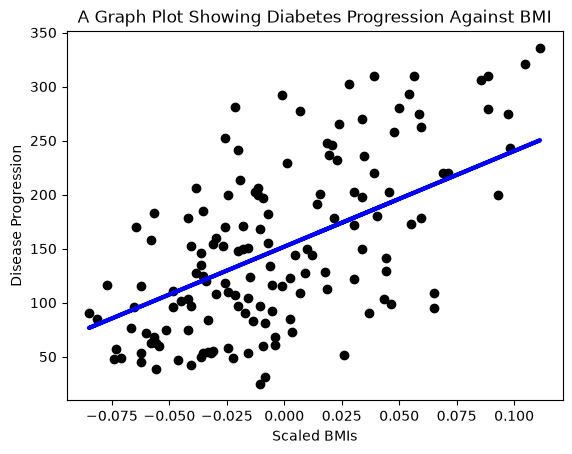

In [8]:
plt.scatter(X_test, y_test, color='black')
plt.plot(X_test, y_pred, color='blue', linewidth=3)
plt.xlabel('Scaled BMIs')
plt.ylabel('Disease Progression')
plt.title('A Graph Plot Showing Diabetes Progression Against BMI')
plt.show()

# Using all features to predict diabeties risk.

In [10]:
X, y = datasets.load_diabetes(return_X_y=True)

print(X.shape)
# (442, 10)

X_train, X_test, y_train, y_test = model_selection.train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42
)

model = linear_model.LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(model.intercept_)
print(model.coef_)

(442, 10)
150.43401223157832
[  32.14928032 -242.82449076  559.98996952  407.63766881 -718.69857577
  396.63703933   10.432395    171.81955335  627.07993787  -21.62312454]


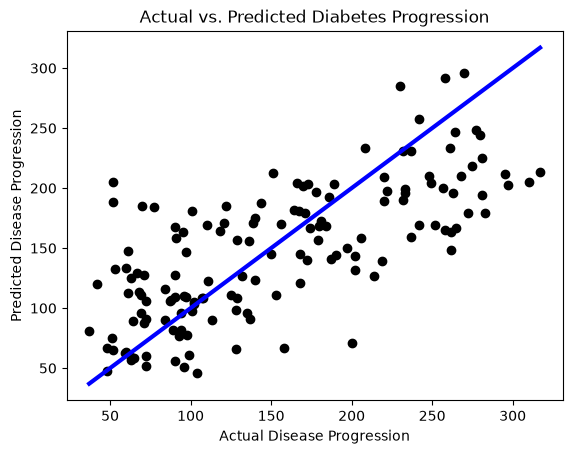

In [13]:
plt.scatter(y_test, y_pred, color="black")

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    color="blue",
    linewidth=3
)

plt.xlabel("Actual Disease Progression")
plt.ylabel("Predicted Disease Progression")
plt.title("Actual vs. Predicted Diabetes Progression")
plt.show()